In [3]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df_merged = pd.read_csv("../hdi-ihdi-democracy-by-country.csv")
df_eiu = pd.read_csv("../democracy-index-eiu.csv")

print("Merged shape:", df_merged.shape)
print("Columns:", df_merged.columns.tolist())
display(df_merged.head())

Merged shape: (194, 8)
Columns: ['country_code', 'Rank', 'HDI', 'IHDI', 'Country', 'Year', 'democracy_eiu', 'democracy_eiu_normalized']


,country_code,Rank,HDI,IHDI,Country,Year,democracy_eiu,democracy_eiu_normalized
0,CHE,1.0,0.967,0.891,Switzerland,2023,9.14,0.914
1,NOR,2.0,0.966,0.903,Norway,2023,9.81,0.981
2,ISL,3.0,0.959,0.91,Iceland,2023,9.45,0.945
3,HKG,4.0,0.956,0.84,Hong Kong,2023,5.24,0.524
4,DNK,5.0,0.952,0.898,Denmark,2023,9.28,0.928


In [7]:
# 1. Convert HDI, IHDI, and democracy_eiu to numeric (turns ".." strings into NaN)
df_merged["HDI"] = pd.to_numeric(df_merged["HDI"], errors="coerce")
df_merged["IHDI"] = pd.to_numeric(df_merged["IHDI"], errors="coerce")
df_merged["democracy_eiu"] = pd.to_numeric(df_merged["democracy_eiu"], errors="coerce")

# 2. Extract 2022 EIU scores from df_eiu and merge by ISO3 Code so we have exact 2022 EIU scores
eiu_2022 = (
    df_eiu[df_eiu["Year"] == 2022][["Code", "Democracy score"]]
    .dropna(subset=["Code"])
    .rename(columns={"Code": "country_code", "Democracy score": "democracy_eiu_2022"})
)
df_analysis = df_merged.merge(eiu_2022, on="country_code", how="left")

print("--- Missingness Audit Across All 194 Countries in df_merged ---")
print(df_analysis[["democracy_eiu_2022", "democracy_eiu", "HDI", "IHDI"]].isna().sum())

# Countries with 2022 EIU & HDI, but missing IHDI (stored as ".." in raw UNDP table)
missing_ihdi = df_analysis[
    df_analysis["democracy_eiu_2022"].notna() & df_analysis["HDI"].notna() & df_analysis["IHDI"].isna()
]
print(f"\nCountries with 2022 EIU & HDI but MISSING IHDI (n={len(missing_ihdi)}):")
print(missing_ihdi[["Country", "democracy_eiu_2022", "HDI"]].sort_values("HDI", ascending=False).to_string(index=False))

# Countries with HDI, but missing 2022 EIU score (mostly microstates, Gulf states, or conflict zones)
missing_eiu = df_analysis[df_analysis["HDI"].notna() & df_analysis["democracy_eiu_2022"].isna()]
print(f"\nCountries with HDI but MISSING 2022 EIU score (n={len(missing_eiu)}):")
print(missing_eiu[["Country", "HDI", "IHDI"]].sort_values("HDI", ascending=False).head(15).to_string(index=False))

# 3. Clean analytical sample using 2022 EIU scores & Threshold 6.0 Comparison
df_clean = df_analysis.dropna(subset=["democracy_eiu_2022", "HDI"]).copy()
df_clean["above_6"] = (df_clean["democracy_eiu_2022"] >= 6.0).astype(int)
df_clean["regime_group"] = np.where(
    df_clean["above_6"] == 1,
    "Score >= 6.0 (Democracies)",
    "Score < 6.0 (Hybrid / Authoritarian)"
)
df_clean["inequality_loss"] = df_clean["HDI"] - df_clean["IHDI"]

print(f"\n--- Group Averages & 95% CIs Around 2022 Democracy Score = 6.0 (n={len(df_clean)}) ---")
for metric in ["HDI", "IHDI", "inequality_loss"]:
    print(f"\nMetric: {metric}")
    for grp, sub in df_clean.dropna(subset=[metric]).groupby("regime_group"):
        mean = sub[metric].mean()
        se = stats.sem(sub[metric])
        ci_low, ci_high = stats.t.interval(0.95, len(sub) - 1, loc=mean, scale=se)
        print(f"  {grp} (n={len(sub)}): mean = {mean:.3f} (95% CI: [{ci_low:.3f}, {ci_high:.3f}])")

--- Missingness Audit Across All 194 Countries in df_merged ---
democracy_eiu_2022    28
democracy_eiu         46
HDI                    1
IHDI                  29
dtype: int64

Countries with 2022 EIU & HDI but MISSING IHDI (n=15):
             Country  democracy_eiu_2022   HDI
             Bahrain                2.52 0.888
               Qatar                3.65 0.875
        Saudi Arabia                2.08 0.875
              Kuwait                3.83 0.847
 Trinidad and Tobago                7.16 0.814
                Cuba                2.65 0.764
               Libya                2.06 0.746
        Turkmenistan                1.66 0.744
              Guyana                6.34 0.742
          Uzbekistan                2.12 0.727
             Lebanon                3.64 0.723
            Suriname                6.95 0.690
   Equatorial Guinea                1.92 0.650
Syrian Arab Republic                1.43 0.557
             Eritrea                2.03 0.493

Countries with

In [9]:
# 1. Pearson & Spearman correlations on the common sample (countries with 2022 EIU, HDI, AND IHDI)
df_common = df_clean.dropna(subset=["IHDI"]).copy()
print(f"--- Common Sample Correlations (n={len(df_common)}) ---")
for metric in ["HDI", "IHDI", "inequality_loss"]:
    r, p_r = stats.pearsonr(df_common["democracy_eiu_2022"], df_common[metric])
    rho, p_rho = stats.spearmanr(df_common["democracy_eiu_2022"], df_common[metric])
    print(f"{metric} vs. 2022 Democracy: Pearson r = {r:.3f} (p={p_r:.2e}), Spearman rho = {rho:.3f} (p={p_rho:.2e})")

# 2. Piecewise / Threshold Regression around 6.0 (HC3 robust standard errors)
df_common["dem_centered"] = df_common["democracy_eiu_2022"] - 6.0

mod_hdi = smf.ols("HDI ~ dem_centered * above_6", data=df_common).fit(cov_type="HC3")
mod_ihdi = smf.ols("IHDI ~ dem_centered * above_6", data=df_common).fit(cov_type="HC3")

print("\n=== Piecewise Regression Around 6.0: HDI (Common Sample) ===")
print(mod_hdi.summary().tables[1])

print("\n=== Piecewise Regression Around 6.0: IHDI (Common Sample) ===")
print(mod_ihdi.summary().tables[1])

# 3. Break Attempt 1: High-HDI (>=0.80) countries below score 6.0 (e.g., wealthy autocracies / petro-states)
high_hdi_autocracies = df_clean[(df_clean["above_6"] == 0) & (df_clean["HDI"] >= 0.80)]
print(f"\n--- High-HDI (>=0.80) Countries Below Score 6.0 (n={len(high_hdi_autocracies)}) ---")
print(high_hdi_autocracies[["Country", "democracy_eiu_2022", "HDI", "IHDI"]].sort_values("HDI", ascending=False).to_string(index=False))

# 4. Break Attempt 2: Check whether using 2023 EIU scores (from df_merged) changes the correlation/jump
r_2023, _ = stats.pearsonr(df_common["democracy_eiu"], df_common["HDI"])
r_ihdi_2023, _ = stats.pearsonr(df_common["democracy_eiu"], df_common["IHDI"])
print(f"\n--- Year Sensitivity Check (2023 EIU vs 2022 EIU on Common Sample) ---")
print(f"2023 EIU vs HDI: r = {r_2023:.3f} | 2023 EIU vs IHDI: r = {r_ihdi_2023:.3f}")

--- Common Sample Correlations (n=150) ---
HDI vs. 2022 Democracy: Pearson r = 0.698 (p=2.91e-23), Spearman rho = 0.713 (p=1.50e-24)
IHDI vs. 2022 Democracy: Pearson r = 0.671 (p=6.16e-21), Spearman rho = 0.688 (p=2.55e-22)
inequality_loss vs. 2022 Democracy: Pearson r = -0.433 (p=3.07e-08), Spearman rho = -0.445 (p=1.15e-08)

=== Piecewise Regression Around 6.0: HDI (Common Sample) ===
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                0.6669      0.026     25.646      0.000       0.616       0.718
dem_centered             0.0191      0.010      1.844      0.065      -0.001       0.039
above_6                  0.0646      0.034      1.890      0.059      -0.002       0.132
dem_centered:above_6     0.0490      0.014      3.571      0.000       0.022       0.076

=== Piecewise Regression Around 6.0: IHDI (Common Sample) ===
             

=== Full Sample HDI (n=165) vs. Excluding High-HDI (<6.0) Outliers (n=153) ===
All Countries (n=165):
  Slope < 6.0: 0.011 (p=0.244) | Jump at 6.0: +0.062 (p=0.065) | Slope change >= 6.0: +0.058 (p=0.000)
Excl. High-HDI <6.0 Outliers (n=153):
  Slope < 6.0: 0.015 (p=0.087) | Jump at 6.0: +0.085 (p=0.007) | Slope change >= 6.0: +0.054 (p=0.000)


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


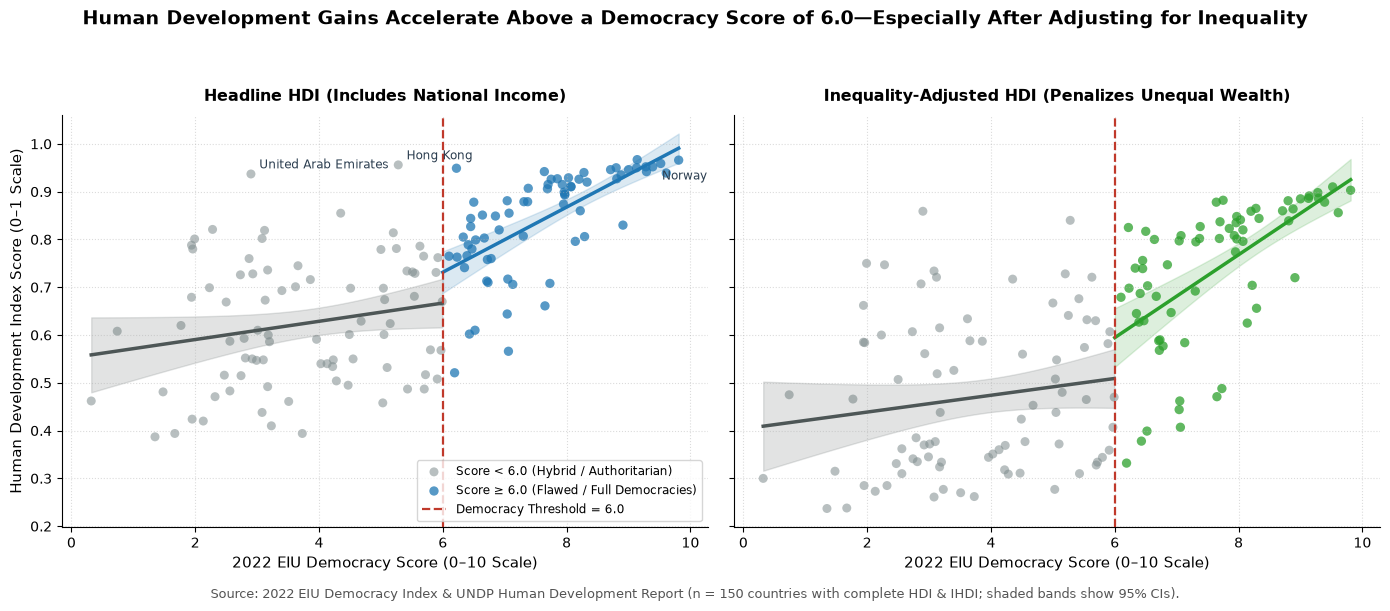

In [10]:
# 1. Exact Break Attempt: Compare piecewise slopes WITH vs. WITHOUT the 12 high-HDI (<6.0) outliers
df_clean["dem_centered"] = df_clean["democracy_eiu_2022"] - 6.0
df_no_rich_aut = df_clean[~((df_clean["above_6"] == 0) & (df_clean["HDI"] >= 0.80))].copy()

mod_hdi_all = smf.ols("HDI ~ dem_centered * above_6", data=df_clean).fit(cov_type="HC3")
mod_hdi_no_out = smf.ols("HDI ~ dem_centered * above_6", data=df_no_rich_aut).fit(cov_type="HC3")

print("=== Full Sample HDI (n=165) vs. Excluding High-HDI (<6.0) Outliers (n=153) ===")
for name, m in [("All Countries (n=165)", mod_hdi_all), ("Excl. High-HDI <6.0 Outliers (n=153)", mod_hdi_no_out)]:
    b_below = m.params["dem_centered"]
    p_below = m.pvalues["dem_centered"]
    b_jump = m.params["above_6"]
    p_jump = m.pvalues["above_6"]
    b_kink = m.params["dem_centered:above_6"]
    p_kink = m.pvalues["dem_centered:above_6"]
    print(f"{name}:")
    print(f"  Slope < 6.0: {b_below:.3f} (p={p_below:.3f}) | Jump at 6.0: +{b_jump:.3f} (p={p_jump:.3f}) | Slope change >= 6.0: +{b_kink:.3f} (p={p_kink:.3f})")

# 2. Create Polished Story-Titled Figure
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

panels = [
    ("HDI", "Headline HDI (Includes National Income)", mod_hdi, "#1f77b4", "n = 150 (Common Sample)"),
    ("IHDI", "Inequality-Adjusted HDI (Penalizes Unequal Wealth)", mod_ihdi, "#2ca02c", "n = 150 (15 Countries Missing IHDI, incl. 4 Gulf States)")
]

for ax, (col, subtitle, model, color, note) in zip(axes, panels):
    # Scatter points
    below = df_common[df_common["above_6"] == 0]
    above = df_common[df_common["above_6"] == 1]
    
    ax.scatter(below["democracy_eiu_2022"], below[col], alpha=0.55, color="#7f8c8d", edgecolors="none", s=42, label="Score < 6.0 (Hybrid / Authoritarian)")
    ax.scatter(above["democracy_eiu_2022"], above[col], alpha=0.75, color=color, edgecolors="none", s=45, label="Score ≥ 6.0 (Flawed / Full Democracies)")
    
    # Piecewise regression lines + 95% CI bands
    for grp_val, x_grid in [(0, np.linspace(df_common["democracy_eiu_2022"].min(), 5.99, 100)),
                            (1, np.linspace(6.0, df_common["democracy_eiu_2022"].max(), 100))]:
        pred_df = pd.DataFrame({"dem_centered": x_grid - 6.0, "above_6": grp_val})
        pred = model.get_prediction(pred_df).summary_frame(alpha=0.05)
        line_col = "#4d5656" if grp_val == 0 else color
        ax.plot(x_grid, pred["mean"], color=line_col, linewidth=2.5)
        ax.fill_between(x_grid, pred["mean_ci_lower"], pred["mean_ci_upper"], color=line_col, alpha=0.16)
    
    # Threshold vertical line at 6.0
    ax.axvline(6.0, color="#c0392b", linestyle="--", linewidth=1.6, label="Democracy Threshold = 6.0")
    ax.set_title(subtitle, fontsize=11.5, fontweight="bold", pad=10)
    ax.set_xlabel("2022 EIU Democracy Score (0–10 Scale)", fontsize=10.5)
    ax.grid(True, linestyle=":", alpha=0.45)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Annotate notable high-income autocratic outliers in HDI panel
outliers_to_label = ["Hong Kong", "United Arab Emirates", "Norway"]
for country in outliers_to_label:
    row = df_common[df_common["Country"] == country]
    if not row.empty:
        x_val = row["democracy_eiu_2022"].values[0]
        y_val = row["HDI"].values[0]
        offset = (-12, -14) if country == "Norway" else (6, 4)
        axes[0].annotate(country, (x_val, y_val), xytext=offset, textcoords="offset points", fontsize=8.5, color="#2c3e50", fontweight="medium")

axes[0].set_ylabel("Human Development Index Score (0–1 Scale)", fontsize=10.5)
axes[0].legend(loc="lower right", frameon=True, fontsize=8.8)

fig.suptitle(
    "Human Development Gains Accelerate Above a Democracy Score of 6.0—Especially After Adjusting for Inequality",
    fontsize=13.5, fontweight="bold", y=0.99
)
fig.text(
    0.5, 0.01,
    "Source: 2022 EIU Democracy Index & UNDP Human Development Report (n = 150 countries with complete HDI & IHDI; shaded bands show 95% CIs).",
    ha="center", fontsize=9, color="#555555"
)

plt.tight_layout(rect=[0, 0.03, 1, 0.94])
plt.savefig("fig_sai_democracy_hdi_threshold.png", dpi=300, bbox_inches="tight")
plt.show()